# 1. Identificación

* **Nombre completo del estudiante:** [Luca Lagos Paciello]
* **Código de la serie asignada:** TPM
* **Nombre o descripción de la variable:** Tasa de Política Monetaria (TPM)
* **Breve explicación:** La Tasa de Política Monetaria (TPM) es la tasa de interés objetivo establecida por el Banco Central. Es el principal instrumento de política monetaria utilizado para influir en la actividad macroeconómica, estimulando la economía en periodos de baja inflación o enfriándola cuando las presiones inflacionarias son altas.

# 2. Importación de bibliotecas
Importamos las bibliotecas necesarias para la manipulación y visualización de los datos de la serie de tiempo.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 3. Carga del archivo
Para ejecutar correctamente el notebook, asegúrate de descargar el archivo `TPM.xlsx` y subirlo a la pestaña lateral de "Archivos" en Google Colab.

In [2]:
file_path = 'TPM.xlsx'
df_raw = pd.read_excel(file_path)
print("Archivo cargado exitosamente.")

Archivo cargado exitosamente.


# 4. Exploración de los datos
Revisamos la estructura original del dataset, identificando cómo viene estructurada la información base.

In [3]:
print("--- Primeras cinco observaciones ---")
display(df_raw.head())

print("\n--- Nombre de las columnas ---")
print(df_raw.columns.tolist())

print("\n--- Cantidad de filas y columnas ---")
print(f"Filas: {df_raw.shape[0]}, Columnas: {df_raw.shape[1]}")

print("\n--- Tipos de datos ---")
print(df_raw.dtypes)

print("\n--- Existencia de valores faltantes ---")
print(df_raw.isnull().sum())

--- Primeras cinco observaciones ---


,"Fecha,TPM"
0,"2020-01-02,1.75"
1,"2020-01-03,1.75"
2,"2020-01-04,"
3,"2020-01-05,"
4,"2020-01-06,1.75"



--- Nombre de las columnas ---
['Fecha,TPM']

--- Cantidad de filas y columnas ---
Filas: 2424, Columnas: 1

--- Tipos de datos ---
Fecha,TPM    object
dtype: object

--- Existencia de valores faltantes ---
Fecha,TPM    0
dtype: int64


# 5. Preparación de la serie
Como en la exploración notamos que la Fecha y la TPM vienen combinadas en una sola columna separada por coma, realizaremos el proceso de imputación y limpieza correspondiente.

In [4]:
# Identificar y separar la columna si viene combinada como 'Fecha,TPM'
if 'Fecha,TPM' in df_raw.columns:
    df = df_raw['Fecha,TPM'].str.split(',', expand=True)
    df.columns = ['Fecha', 'TPM']
else:
    df = df_raw.copy()

# Convertirla a formato de fecha
df['Fecha'] = pd.to_datetime(df['Fecha'], errors='coerce')

# Identificar la columna que contiene los valores numéricos y transformarla
df['TPM'] = pd.to_numeric(df['TPM'], errors='coerce')

# Ordenar cronológicamente las observaciones
df = df.sort_values(by='Fecha').reset_index(drop=True)

print("Datos preparados y ordenados cronológicamente. Vista previa:")
display(df.head())

Datos preparados y ordenados cronológicamente. Vista previa:


,Fecha,TPM
0,2020-01-02,1.75
1,2020-01-03,1.75
2,2020-01-04,NaN
3,2020-01-05,NaN
4,2020-01-06,1.75


# 6. Elaboración del gráfico
A continuación representamos gráficamente la evolución de la serie de tiempo de la TPM.

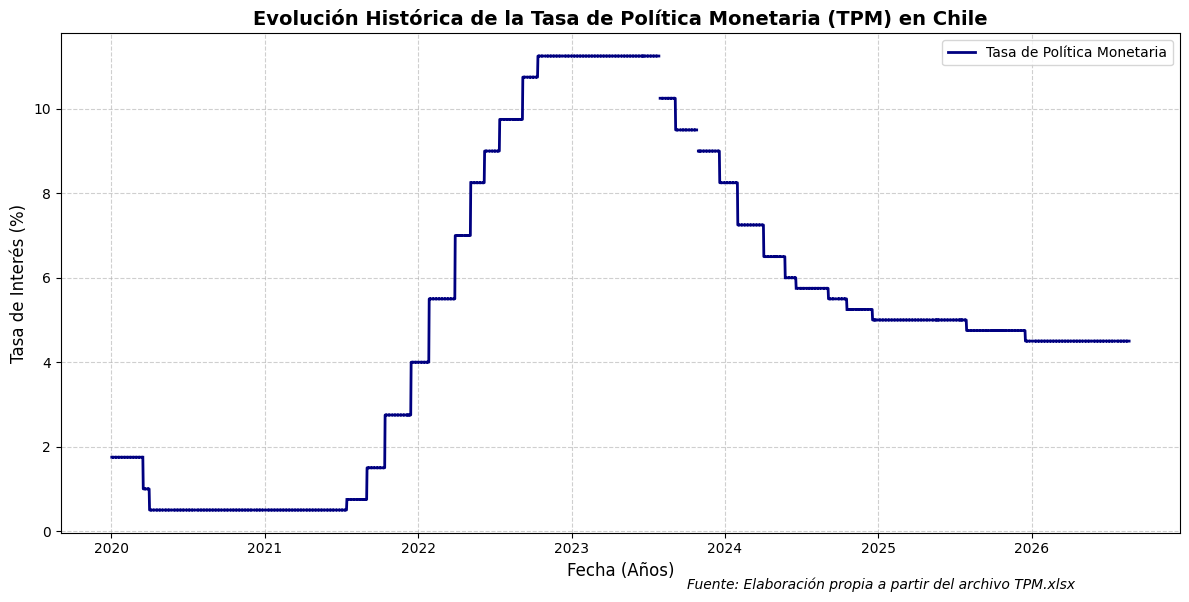

In [5]:
plt.figure(figsize=(12, 6))
plt.plot(df['Fecha'], df['TPM'], color='navy', linewidth=2, label='Tasa de Política Monetaria')

# Título y etiquetas descriptivas
plt.title('Evolución Histórica de la Tasa de Política Monetaria (TPM) en Chile', fontsize=14, fontweight='bold')
plt.xlabel('Fecha (Años)', fontsize=12)
plt.ylabel('Tasa de Interés (%)', fontsize=12)

# Leyenda y estilo
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.6)

# Fuente de los datos
plt.figtext(0.9, 0.01, 'Fuente: Elaboración propia a partir del archivo TPM.xlsx', ha='right', fontsize=10, fontstyle='italic')

plt.tight_layout()
plt.show()

# 7. Interpretación

La Tasa de Política Monetaria (TPM) exhibe marcadas fluctuaciones entre enero de 2020 y agosto de 2026, reflejando el ciclo económico chileno. Durante 2020 y la primera mitad de 2021, la tendencia se mantuvo plana en un mínimo histórico de 0,5%, un periodo de alta expansividad monetaria por la pandemia. Posteriormente, se observa un drástico y acelerado aumento escalonado que llevó la tasa a un máximo restrictivo de 11,25% a finales de 2022, respondiendo a fuertes presiones inflacionarias. A partir de 2023, la tendencia se invierte hacia la baja, mostrando un ciclo de recortes continuos hasta estabilizarse gradualmente en 4,5% a mediados de 2026. El patrón general demuestra una política monetaria contracíclica, caracterizada por una rápida reacción alcista ante la inflación, seguida de una normalización paulatina hacia niveles más neutrales conforme se controla la situación macroeconómica.